# PCA, Ensemble Learning, and Diabetes Prediction

## Objective

This notebook uses one classification dataset to demonstrate three related ideas:

1. **Principal Component Analysis (PCA):** standardize the predictor variables, reduce their dimensionality, and visualize the observations in two dimensions.
2. **Ensemble learning:** compare a single decision tree with a bagging model (Random Forest) and a boosting model (Gradient Boosting).
3. **Diabetes prediction:** build and evaluate a classification model using a leakage-safe preprocessing workflow.

The analysis uses the supplied **Pima Indians Diabetes** CSV file. The target column is `Outcome` (`1` = diabetes-positive and `0` = diabetes-negative). The dataset has 768 rows, eight predictor columns, and one target column.


## 1. Import libraries and load the dataset

We use `pandas` and `NumPy` for data handling, `matplotlib` and `seaborn` for visualizations, and scikit-learn for preprocessing, PCA, model training, and evaluation.

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)

# Load the CSV file
path = [Path("diabetes.csv")]
DATA_PATH = next((path for path in path if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "diabetes.csv was not found. Place it in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Loaded: diabetes.csv
Dataset shape: 768 rows × 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Understand the data (EDA)

Exploratory Data Analysis (EDA) helps us understand the dataset before modelling. We inspect its dimensions, data types, summary statistics, missing values, duplicate records, target balance, and feature distributions.

In [4]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe().T)

print("\nMissing values recorded as NaN:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values recorded as NaN:


,missing_values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0


### 2.1 Identify zero values that represent missing measurements

The CSV does not contain `NaN` values, but zero is not a plausible measured value for several clinical variables in this dataset. We therefore treat zero as missing for **Glucose, BloodPressure, SkinThickness, Insulin, and BMI**. We do not replace zero in `Pregnancies`, because zero pregnancies is valid, and we do not alter zero in the target.

This is a dataset-specific cleaning assumption. The values are not deleted; they are imputed later using medians learned from the training data.

In [5]:
# Columns where 0 is impossible
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Count zeros per column, highest first
zero_counts = df[zero_as_missing].eq(0).sum().sort_values(ascending=False)

# Summary table: absolute zero counts + % of rows affected
zero_summary = zero_counts.to_frame("zero_values_treated_as_missing")
zero_summary["percentage_of_rows"] = (zero_summary["zero_values_treated_as_missing"] / len(df) * 100).round(1)
display(zero_summary)

# Create a copy so original df stays untouched
df_clean = df.copy()

# Replace invalid 0s with NaN to treat them as missing
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)
print("Total missing values after converting invalid zeros to NaN:")
display(df_clean.isna().sum().to_frame("missing_values"))

,zero_values_treated_as_missing,percentage_of_rows
Insulin,374,48.7
SkinThickness,227,29.6
BloodPressure,35,4.6
BMI,11,1.4
Glucose,5,0.7


Total missing values after converting invalid zeros to NaN:


,missing_values
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### 2.2 Target distribution

The target is not perfectly balanced. This matters because a model can achieve reasonable accuracy by predicting the more common class too often. We therefore report precision, recall, and F1-score in addition to accuracy.

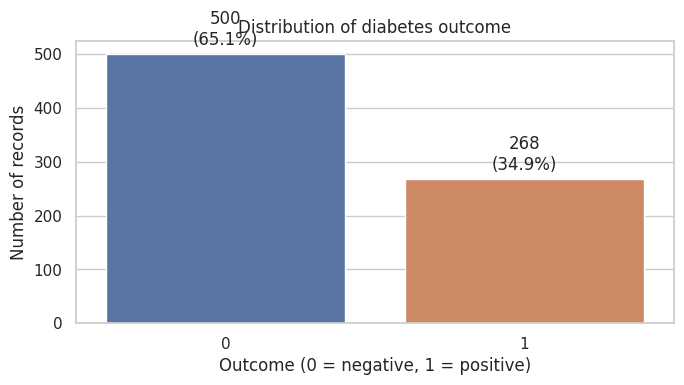

,count,percentage
Outcome,,
0,500,65.1
1,268,34.9


In [6]:
# Class balance
class_counts = df["Outcome"].value_counts().sort_index()
class_percentages = df["Outcome"].value_counts(normalize=True).sort_index() * 100

# Bar chart of class distribution
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="Outcome", hue="Outcome", legend=False, ax=ax)
ax.set_title("Distribution of diabetes outcome")
ax.set_xlabel("Outcome (0 = negative, 1 = positive)")
ax.set_ylabel("Number of records")

# Annotate each bar with the raw count and its share of the dataset
for patch, label in zip(ax.patches, class_counts.values):
    ax.annotate(f"{label}\n({label / len(df):.1%})",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
plt.tight_layout()
plt.show()

# Tabular view of the distribution
display(pd.DataFrame({"count": class_counts, "percentage": class_percentages.round(1)}))

### 2.3 Feature distributions and relationships

Histograms show the spread and skewness of the eight predictors after invalid zero values have been marked as missing. The correlation heatmap provides a quick view of linear associations; correlation does not establish causation.

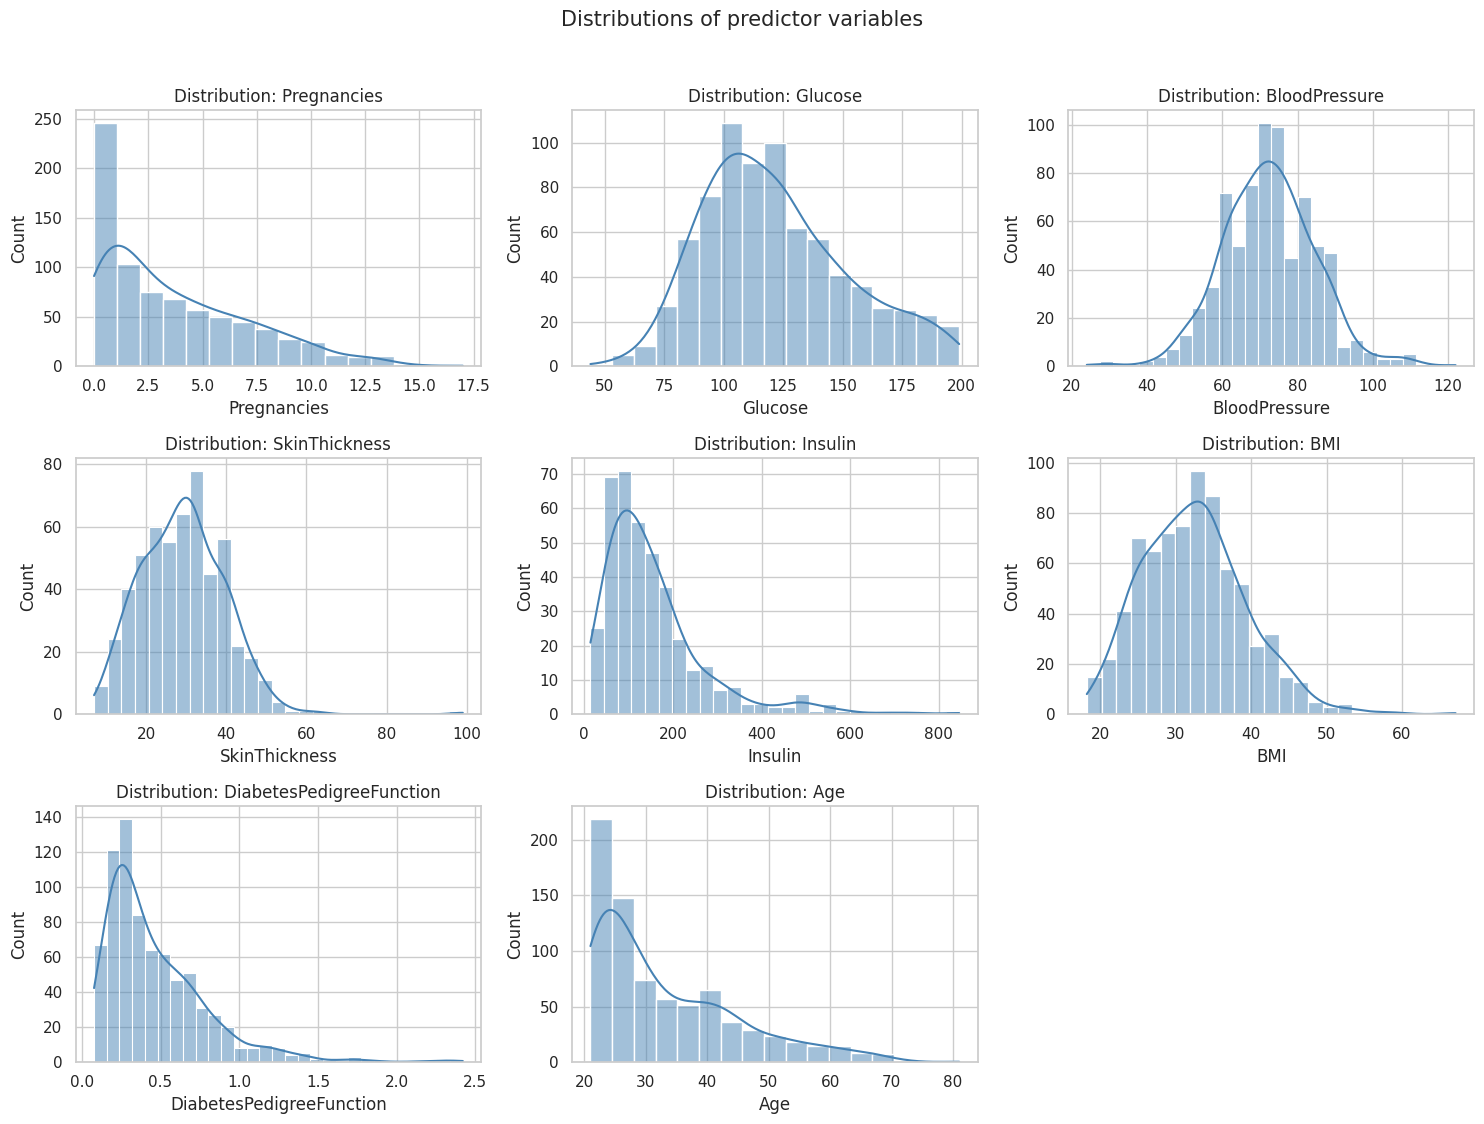

In [7]:
feature_cols = [column for column in df_clean.columns if column != "Outcome"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
for i, feature in enumerate(feature_cols):
    sns.histplot(df_clean[feature], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution: {feature}")
    axes[i].set_xlabel(feature)
axes[-1].axis("off")
plt.suptitle("Distributions of predictor variables", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

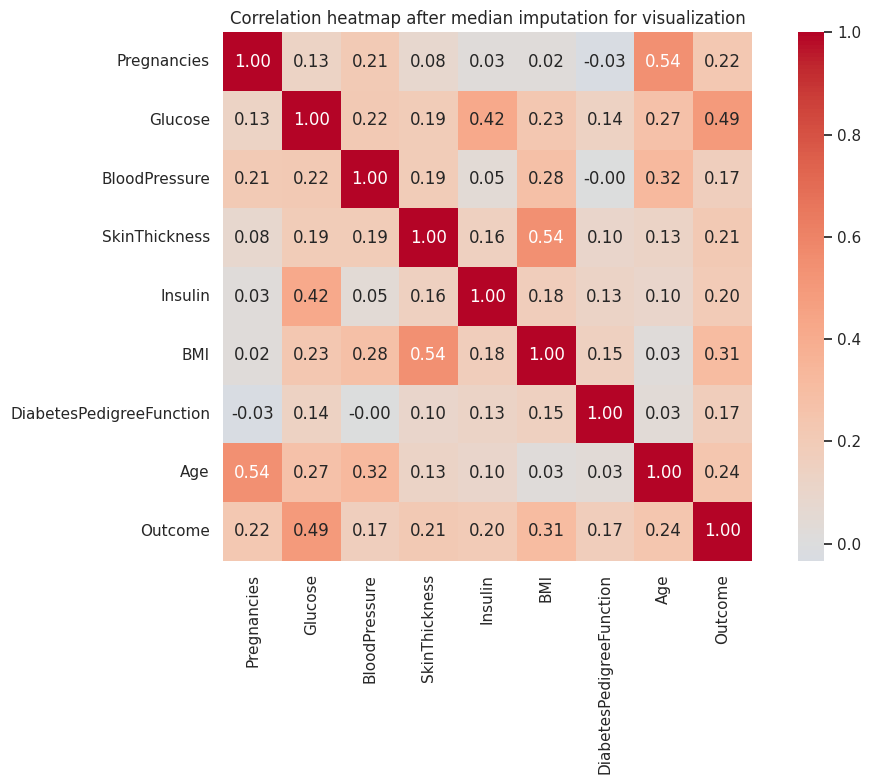

In [ ]:
# For the correlation plot only, fill missing entries with feature medians.
eda_for_corr = df_clean.copy()
eda_for_corr[feature_cols] = SimpleImputer(strategy="median").fit_transform(eda_for_corr[feature_cols])

plt.figure(figsize=(11, 8))
sns.heatmap(eda_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap after median imputation for visualization")
plt.tight_layout()
plt.show()

### EDA observations

- The dataset contains **768 observations**, eight predictors, and one binary target.
- There are no literal `NaN` values in the original CSV. However, zero-coded entries in the five variables above need to be handled as missing measurements.
- `Insulin` and `SkinThickness` contain particularly large numbers of zero-coded entries, so dropping every affected row would discard substantial information. Median imputation is a practical baseline.
- The target classes are imbalanced: there are more records with `Outcome = 0` than `Outcome = 1`. This motivates examining recall and F1-score, not accuracy alone.

## 3. Topic 1 — Principal Component Analysis (PCA)

### What is PCA?

Principal Component Analysis is an **unsupervised dimensionality-reduction technique**. It transforms the original, possibly correlated predictors into new variables called *principal components*.

- The first principal component (PC1) captures the largest possible amount of variation in the standardized data.
- PC2 captures the largest amount of remaining variation
- Later components capture progressively smaller amounts of remaining variation.

### Why standardize before PCA?

PCA is affected by variable scale. For example, insulin values can be numerically much larger than the diabetes values. Without standardization, variables with larger numeric scales could dominate the components. .

The target `Outcome` is **not** included in PCA; it is only used to colour the scatter plot afterwards.

In [8]:
X = df_clean[feature_cols].copy()
y = df_clean["Outcome"].astype(int).copy()

pca_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_standardized = pca_preprocessor.fit_transform(X)
pca_full = PCA()
X_pca = pca_full.fit_transform(X_standardized)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Choose the smallest number of components that retains at least 90% variance.
variance_threshold = 0.90
n_components_90 = int(np.argmax(cumulative_variance >= variance_threshold) + 1)

print(f"Variance explained by PC1 and PC2: {cumulative_variance[1]:.1%}")
print(f"Components needed to reach at least {variance_threshold:.0%} variance: {n_components_90}")
print(f"Cumulative variance retained by {n_components_90} components: {cumulative_variance[n_components_90 - 1]:.1%}")

Variance explained by PC1 and PC2: 47.2%
Components needed to reach at least 90% variance: 7
Cumulative variance retained by 7 components: 95.2%


### 3.1 Scree plot and component selection

A scree plot displays the variance explained by each component. The cumulative line shows how much total variance is retained as components are added. Here, we select the **smallest number of components that reaches at least 90% cumulative explained variance**. This is a transparent variance-retention rule; it is not a guarantee that the components preserve all information useful for predicting the target.

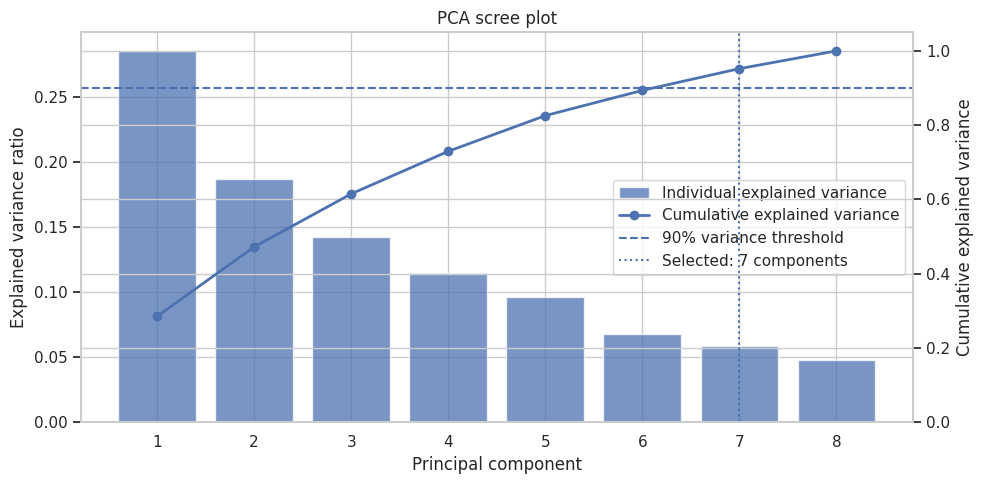

,component,individual_variance,cumulative_variance
0,PC1,0.2854,0.2854
1,PC2,0.1869,0.4723
2,PC3,0.1427,0.6150
3,PC4,0.1146,0.7296
4,PC5,0.0961,0.8257
5,PC6,0.0679,0.8936
6,PC7,0.0586,0.9521
7,PC8,0.0479,1.0000


In [9]:
components = np.arange(1, len(explained_variance) + 1)
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(components, explained_variance, alpha=0.75, label="Individual explained variance")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Explained variance ratio")
ax1.set_xticks(components)
ax1.set_title("PCA scree plot")

ax2 = ax1.twinx()
ax2.plot(components, cumulative_variance, marker="o", linewidth=2,
         label="Cumulative explained variance")
ax2.axhline(variance_threshold, linestyle="--", linewidth=1.5,
            label=f"{variance_threshold:.0%} variance threshold")
ax2.axvline(n_components_90, linestyle=":", linewidth=1.5,
            label=f"Selected: {n_components_90} components")
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.05)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout()
plt.show()

variance_table = pd.DataFrame({
    "component": [f"PC{i}" for i in components],
    "individual_variance": explained_variance,
    "cumulative_variance": cumulative_variance
})
display(variance_table.round(4))

**Interpretation:** PC1 and PC2 together provide a two-dimensional summary for plotting, but they retain less than half of the total predictor variance in this dataset. The selected component count is therefore based on the 90% cumulative-variance rule, rather than assuming that two components are sufficient for all analytical purposes.

### 3.2 Visualize the first two principal components

Each point represents one patient record. Colour indicates the observed `Outcome`; it was not used to construct the PCA components. If the two colours overlap, the first two components do not cleanly separate the classes in two dimensions. That does not necessarily mean the original eight features contain no useful predictive information.

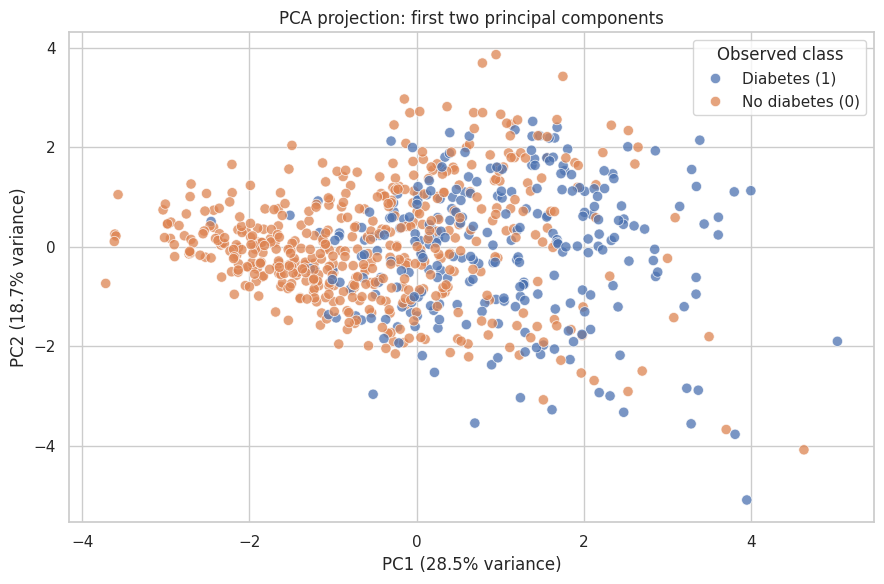

In [10]:
pca_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Outcome": y.map({0: "No diabetes (0)", 1: "Diabetes (1)"}).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="Outcome",
                alpha=0.75, s=55)
plt.title("PCA projection: first two principal components")
plt.xlabel(f"PC1 ({explained_variance[0]:.1%} variance)")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%} variance)")
plt.legend(title="Observed class")
plt.tight_layout()
plt.show()

### 3.3 What do the components represent?

A component loading describes how strongly an original standardized feature contributes to a principal component. Large absolute loadings indicate stronger contributions; the sign indicates direction, but the sign of an entire PCA component can be flipped without changing the PCA solution.

In [11]:
loadings = pd.DataFrame(
    pca_full.components_[:2].T,
    index=feature_cols,
    columns=["PC1_loading", "PC2_loading"]
)
display(loadings.reindex(loadings.abs().max(axis=1).sort_values(ascending=False).index).round(3))

,PC1_loading,PC2_loading
Pregnancies,0.301,0.558
Age,0.386,0.518
Glucose,0.424,-0.082
BMI,0.402,-0.398
SkinThickness,0.397,-0.309
BloodPressure,0.377,0.172
Insulin,0.307,-0.236
DiabetesPedigreeFunction,0.157,-0.273


### PCA conclusion

PCA creates a compact representation of the eight predictors and helps visualize their structure. The scree plot provides an evidence-based component choice, while the two-dimensional scatter plot shows how much (or how little) the first two components separate the observed diabetes classes. PCA is useful for exploration and dimensionality reduction, but it does not automatically improve a classifier, and the components can be harder to interpret than the original clinical measurements.

## 4. Topic 2 — Ensemble Learning

Ensemble learning combines predictions from multiple models to obtain a model that can generalize better than an individual learner.

### Method 1: Bagging — Random Forest

**Bagging** (bootstrap aggregating) trains multiple models on bootstrap samples of the training data and combines their predictions. A Random Forest is a bagging-based ensemble of decision trees; it also considers random subsets of features when splitting. Averaging/voting across diverse trees generally reduces the variance of a single decision tree.

### Method 2: Boosting — Gradient Boosting

**Boosting** trains learners sequentially. Each new learner is added to improve the current ensemble, often by focusing on residual errors or the mistakes that remain. Gradient Boosting builds an additive model in stages, optimizing a loss function. It can reduce bias and capture complex patterns, although it may be sensitive to noisy data and hyperparameter choices.

### Evaluation design

We use the same stratified 80/20 train-test split for all three models. Imputation is fitted on the training data within each pipeline, preventing information from the test set from leaking into preprocessing. Tree-based methods do not require feature scaling, so only median imputation is applied here.

In [12]:
# One fixed, stratified split is reused for the ensemble comparison and diabetes model.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training positive-class rate:", f"{y_train.mean():.1%}")
print("Testing positive-class rate:", f"{y_test.mean():.1%}")

Training set: (614, 8)
Testing set: (154, 8)
Training positive-class rate: 34.9%
Testing positive-class rate: 35.1%


### 4.1 Train the single tree, Random Forest, and Gradient Boosting models

In [14]:
ensemble_models = {
    "Decision Tree (single model)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest (bagging)": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting (boosting)": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

ensemble_results = []
ensemble_fitted = {}

for model_name, estimator in ensemble_models.items():
    model_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator)
    ])
    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)
    probabilities = model_pipeline.predict_proba(X_test)[:, 1]

    ensemble_fitted[model_name] = model_pipeline
    ensemble_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

ensemble_comparison = pd.DataFrame(ensemble_results).set_index("Model")
display(ensemble_comparison.style.format("{:.3f}"))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree (single model),0.682,0.553,0.481,0.515,0.636
Random Forest (bagging),0.740,0.659,0.537,0.592,0.816
Gradient Boosting (boosting),0.760,0.689,0.574,0.626,0.831


### 4.2 Compare the models visually

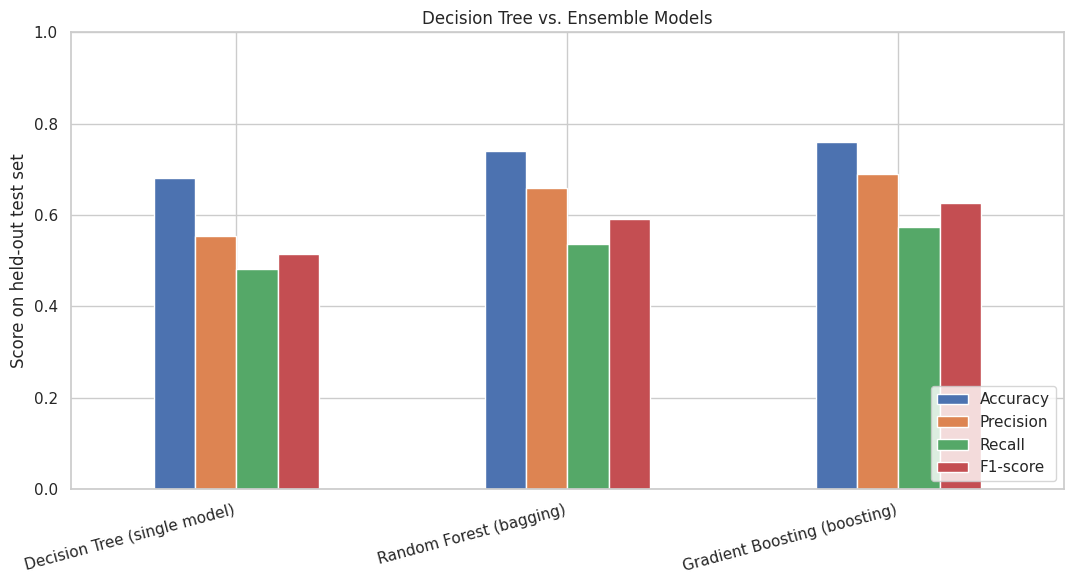

In [15]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score"]
ensemble_comparison[metrics_to_plot].plot(kind="bar", figsize=(11, 6), ylim=(0, 1))
plt.title("Decision Tree vs. Ensemble Models")
plt.ylabel("Score on held-out test set")
plt.xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.3 Interpret the ensemble comparison

The code below calculates the improvement in accuracy and F1-score over the single decision tree. Use the printed values together with the comparison table when writing up the results. An ensemble is not guaranteed to win on every dataset or metric; the conclusion should follow the measured test results.

In [16]:
baseline_name = "Decision Tree (single model)"
rf_name = "Random Forest (bagging)"
gb_name = "Gradient Boosting (boosting)"

for model_name in [rf_name, gb_name]:
    acc_change = ensemble_comparison.loc[model_name, "Accuracy"] - ensemble_comparison.loc[baseline_name, "Accuracy"]
    f1_change = ensemble_comparison.loc[model_name, "F1-score"] - ensemble_comparison.loc[baseline_name, "F1-score"]
    print(f"{model_name} vs. Decision Tree:")
    print(f"  Accuracy change: {acc_change:+.1%} (percentage-point difference)")
    print(f"  F1-score change: {f1_change:+.1%} (percentage-point difference)\n")

best_accuracy_model = ensemble_comparison["Accuracy"].idxmax()
best_f1_model = ensemble_comparison["F1-score"].idxmax()
print("Best ensemble-comparison model by accuracy:", best_accuracy_model)
print("Best ensemble-comparison model by F1-score:", best_f1_model)

Random Forest (bagging) vs. Decision Tree:
  Accuracy change: +5.8% (percentage-point difference)
  F1-score change: +7.7% (percentage-point difference)

Gradient Boosting (boosting) vs. Decision Tree:
  Accuracy change: +7.8% (percentage-point difference)
  F1-score change: +11.1% (percentage-point difference)

Best ensemble-comparison model by accuracy: Gradient Boosting (boosting)
Best ensemble-comparison model by F1-score: Gradient Boosting (boosting)


### Why can the ensemble models perform better?

A single decision tree can change substantially when the training data changes; this is called **high variance**. Random Forest reduces this instability by averaging many trees trained with different bootstrap samples and feature subsets. Gradient Boosting builds a sequence of trees where later stages improve the current model's remaining errors. These mechanisms can produce stronger generalization than one tree.

The improvement depends on the dataset and settings. More complex ensembles can also overfit, require more computation, and be less interpretable than a single tree. The held-out test metrics determine which model performed best in this experiment.

## 5. Topic 3 — Diabetes Prediction

For the main diabetes-prediction task, we use **Logistic Regression**. It is a useful classification baseline because it estimates the probability of the positive class .

### Preprocessing and modelling decisions

1. **Target and predictors:** `Outcome` is the target; the other eight columns are predictors.
2. **Invalid zeros:** the five variables identified during EDA have zero values replaced with missing values.
3. **Train/test split:** the data are split 80/20 using stratification so the class proportions are approximately preserved.
4. **Imputation:** missing values are replaced by the median calculated from the training set only.
5. **Scaling:** `StandardScaler` standardizes predictors using training-set statistics. This is important for Logistic Regression because the features have different units and magnitudes.
6. **Class weighting:** `class_weight="balanced"` gives the less frequent positive class additional weight during training. This can improve detection of positive cases, although precision may fall as more cases are flagged.

All preprocessing is contained in a scikit-learn `Pipeline`. This ensures that the imputer and scaler are fitted on training data only and then applied to the held-out test data.

### 5.1 Train the Logistic Regression pipeline

In [17]:
diabetes_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

diabetes_model.fit(X_train, y_train)
y_pred = diabetes_model.predict(X_test)
y_probability = diabetes_model.predict_proba(X_test)[:, 1]

print("Model training complete.")

Model training complete.


### 5.2 Evaluate using accuracy, precision, recall, F1-score, and ROC-AUC

- **Accuracy:** proportion of all test predictions that are correct.
- **Precision:** among records predicted positive, the proportion that are actually positive.
- **Recall (sensitivity):** among actual positive records, the proportion correctly identified. This is especially important when missed positive cases are costly.
- **F1-score:** harmonic mean of precision and recall; useful when both matter.
- **ROC-AUC:** measures how well the model ranks positive cases above negative cases across possible classification thresholds. A value of 0.5 is similar to random ranking; 1.0 is perfect ranking.

In [18]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall (sensitivity)": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

metric_table = pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"])
display(metric_table.style.format("{:.3f}"))

print("Classification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No diabetes (0)", "Diabetes (1)"],
    digits=3,
    zero_division=0
))

,Score
Accuracy,0.734
Precision,0.603
Recall (sensitivity),0.704
F1-score,0.650
ROC-AUC,0.813


Classification report:
                 precision    recall  f1-score   support

No diabetes (0)      0.824     0.750     0.785       100
   Diabetes (1)      0.603     0.704     0.650        54

       accuracy                          0.734       154
      macro avg      0.714     0.727     0.717       154
   weighted avg      0.747     0.734     0.738       154



### 5.3 Confusion matrix

The confusion matrix separates correct and incorrect predictions. In the matrix below, rows are the actual classes and columns are the predicted classes.

,Predicted: No diabetes (0),Predicted: Diabetes (1)
Actual: No diabetes (0),75,25
Actual: Diabetes (1),16,38


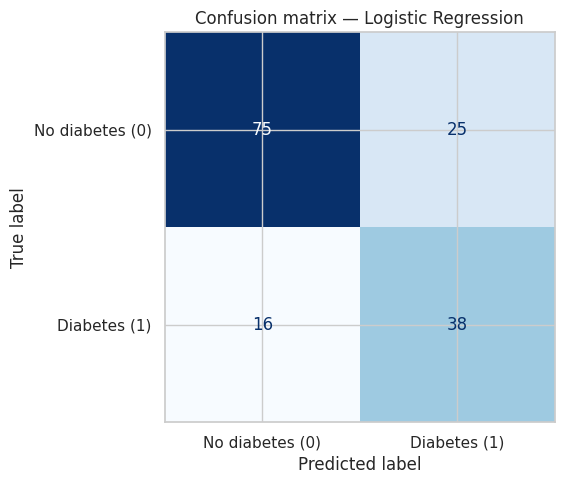

True negatives (TN): 75
False positives (FP): 25
False negatives (FN): 16
True positives (TP): 38
Specificity: 75.0%


In [19]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(
    cm,
    index=["Actual: No diabetes (0)", "Actual: Diabetes (1)"],
    columns=["Predicted: No diabetes (0)", "Predicted: Diabetes (1)"]
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes (0)", "Diabetes (1)"]
).plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Confusion matrix — Logistic Regression")
plt.tight_layout()
plt.show()

# Extract the four confusion-matrix counts for a plain-language interpretation.
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp) if (tn + fp) else np.nan
print(f"True negatives (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP): {tp}")
print(f"Specificity: {specificity:.1%}")

### 5.4 Interpret the result in the context of diabetes prediction

The next cell creates a short interpretation from the actual test-set results, rather than relying on hard-coded numbers. In practical terms:

- A **false negative** is a person with diabetes whom the model predicts as negative. This is a particularly important error to monitor in a screening context.
- A **false positive** is a person without diabetes whom the model predicts as positive. This can lead to unnecessary follow-up testing or concern.
- Higher recall means fewer actual positive cases are missed, but it can come with lower precision and more false positives.

A probability threshold of 0.5 is used by default. In a real screening workflow, the threshold should be selected with clinical experts based on the relative costs of false negatives and false positives. A model prediction must never replace confirmatory testing or professional medical judgment.

In [20]:
print(f"On the held-out test set, the model achieved {metrics['Accuracy']:.1%} accuracy.")
print(f"It identified {tp} of {tp + fn} actual diabetes-positive records (recall = {metrics['Recall (sensitivity)']:.1%}).")
print(f"Of the {tp + fp} records predicted positive, {tp} were actually positive (precision = {metrics['Precision']:.1%}).")
print(f"The model missed {fn} positive records (false negatives) and incorrectly flagged {fp} negative records (false positives).")
print(f"The F1-score was {metrics['F1-score']:.3f}, and ROC-AUC was {metrics['ROC-AUC']:.3f}.")
print("\nInterpretation: evaluate the balance between finding positive cases (recall) and avoiding incorrect positive alerts (precision).")

On the held-out test set, the model achieved 73.4% accuracy.
It identified 38 of 54 actual diabetes-positive records (recall = 70.4%).
Of the 63 records predicted positive, 38 were actually positive (precision = 60.3%).
The model missed 16 positive records (false negatives) and incorrectly flagged 25 negative records (false positives).
The F1-score was 0.650, and ROC-AUC was 0.813.

Interpretation: evaluate the balance between finding positive cases (recall) and avoiding incorrect positive alerts (precision).


## 6. Overall conclusions

### PCA

PCA transformed the eight standardized predictors into orthogonal components. The scree plot showed how much variance each component retained, and the chosen number of components was the minimum needed to cross the 90% cumulative-variance threshold. The first-two-component scatter plot provided a visual summary, but two components do not retain all information in the predictors.

### Ensemble learning

The Decision Tree, Random Forest, and Gradient Boosting models were evaluated on the same held-out test set. Random Forest demonstrates **bagging**, while Gradient Boosting demonstrates **boosting**. The comparison table and metric chart show whether combining learners improved accuracy, precision, recall, and F1-score for this dataset.

### Diabetes prediction

The Logistic Regression pipeline used median imputation and standardization without fitting preprocessing steps on the test set. Its confusion matrix and classification metrics describe the trade-off between missed positive cases and false alarms. Accuracy alone is insufficient for an imbalanced health-related classification problem, so recall, precision, F1-score, and ROC-AUC are also reported.

### Limitations and responsible use

- The dataset contains only 768 records, so performance estimates can vary with a different train/test split.
- It is a specific, historically collected dataset and may not represent other populations, healthcare settings, or current practice.
